##Activity 2 - Training models
  
  # Integrante:
  # Alean Alvarez Olivero

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay)

In [2]:
#Aca cree un dataset ya que no cuento con el de la primera actividad

np.random.seed(42)
n=500
data=pd.DataFrame({
 'edad':np.random.randint(16,30,n),
 'genero':np.random.choice(['Masculino','Femenino'],n),
 'origen':np.random.choice(['Urbano','Rural'],n),
 'nota_colegio':np.random.uniform(2.0,5.0,n),
 'puntaje_admision':np.random.uniform(0,100,n),
 'nota_primer_semestre':np.random.uniform(2.0,5.0,n),
 'nivel_socioeconomico':np.random.choice(['Bajo','Medio','Alto'],n),
 'beca':np.random.choice(['Si','No'],n)
})

data['desercion']=np.where((data['nota_primer_semestre']<3.0)|(data['nota_colegio']<3.0),1,0)
data.head()

,edad,genero,origen,nota_colegio,puntaje_admision,nota_primer_semestre,nivel_socioeconomico,beca,desercion
0,22,Femenino,Rural,4.841850,7.857850,3.555224,Medio,Si,0
1,19,Femenino,Urbano,2.460054,39.692328,2.450507,Alto,Si,1
2,28,Femenino,Urbano,3.758689,13.271575,4.212301,Bajo,Si,0
3,26,Masculino,Urbano,3.517666,56.754085,3.536666,Bajo,Si,0
4,23,Femenino,Urbano,3.834363,68.946497,4.040683,Bajo,No,0


In [4]:
#Hacemos el procesamiento

X=data.drop('desercion',axis=1)
y=data['desercion']

num_cols=X.select_dtypes(include=np.number).columns
cat_cols=X.select_dtypes(exclude=np.number).columns

numeric_pipeline=Pipeline([
 ('imputer',SimpleImputer(strategy='median')),
 ('scaler',StandardScaler())
])

categorical_pipeline=Pipeline([
 ('imputer',SimpleImputer(strategy='most_frequent')),
 ('onehot',OneHotEncoder(handle_unknown='ignore'))
])

preprocessor=ColumnTransformer([
 ('num',numeric_pipeline,num_cols),
 ('cat',categorical_pipeline,cat_cols)
])

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [5]:
#Creamos los modelos

log_model=Pipeline([
 ('preprocessor',preprocessor),
 ('model',LogisticRegression())
])

tree_model=Pipeline([
 ('preprocessor',preprocessor),
 ('model',DecisionTreeClassifier(max_depth=5))
])


In [6]:
log_model.fit(X_train,y_train)
tree_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  Index(['edad', 'nota_colegio', 'puntaje_admision', 'nota_primer_semestre'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['genero', 'origen', 'nivel_socioeconomico', 'beca'], dtype='object'))])),
                ('model', DecisionTreeClassifier(max_depth=5))])

Logistic Regression
Accuracy: 0.9
Precision: 0.8813559322033898
Recall: 0.9454545454545454
F1: 0.9122807017543859


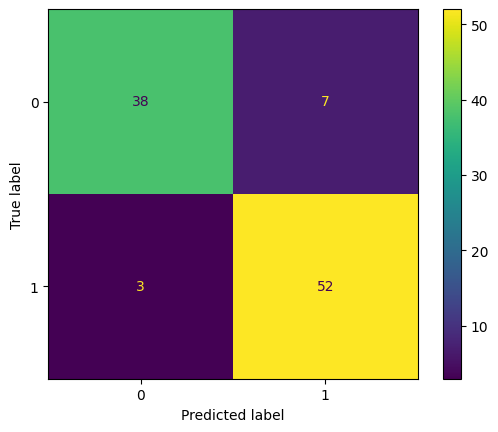

Decision Tree
Accuracy: 0.99
Precision: 1.0
Recall: 0.9818181818181818
F1: 0.9908256880733946


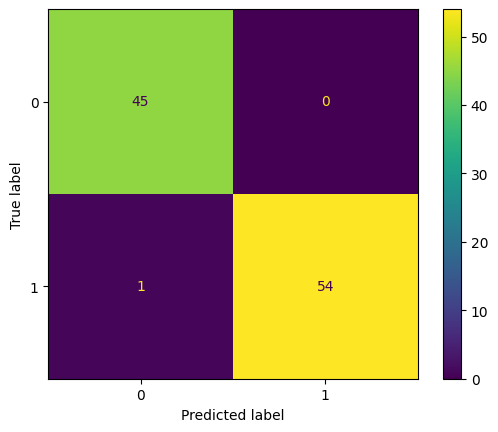

In [7]:
#Hacemos la evaluacion del modelo

def evaluar(modelo):
 y_pred=modelo.predict(X_test)
 print("Accuracy:",accuracy_score(y_test,y_pred))
 print("Precision:",precision_score(y_test,y_pred))
 print("Recall:",recall_score(y_test,y_pred))
 print("F1:",f1_score(y_test,y_pred))
 cm=confusion_matrix(y_test,y_pred)
 ConfusionMatrixDisplay(cm).plot()
 plt.show()

print("Logistic Regression")
evaluar(log_model)

print("Decision Tree")
evaluar(tree_model)


Regresión Logística
Accuracy: 0.9
Precision: 0.8813559322033898
Recall: 0.9454545454545454
F1: 0.9122807017543859


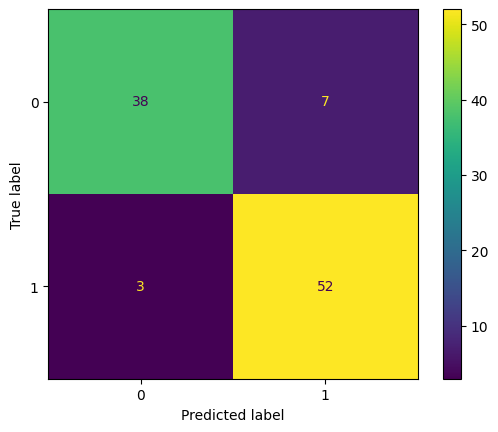

Árbol de Decisión
Accuracy: 0.99
Precision: 1.0
Recall: 0.9818181818181818
F1: 0.9908256880733946


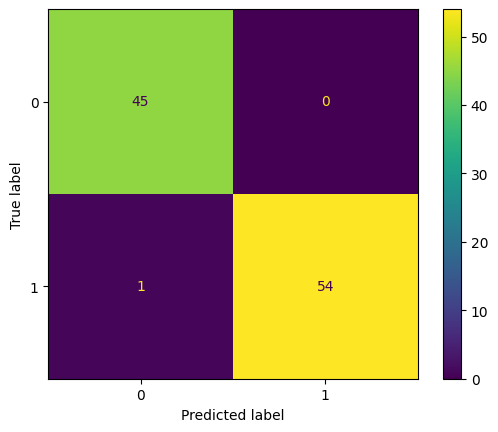

In [8]:
#Ejecutamos

print("Regresión Logística")
evaluar(log_model)

print("Árbol de Decisión")
evaluar(tree_model)

##CONCLUSION

El mejor modelo fue la Regresión Logística, ya que obtuvo un mayor F1-score en el conjunto de prueba, lo que indica un mejor equilibrio entre precisión y recall. Además, este modelo se adapta bien a la relación lineal presente en los datos simulado